# Day 18 — Model comparison and selection

All candidates scored on the validation set, with 95% bootstrap intervals. The winner is chosen by the protocol locked in `docs/results_classical.md` (committed before this notebook was run). Test set untouched.

In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from idxlab.clean import clean_ticker_data
from idxlab.config import load_config
from idxlab.data import DataLoader
from idxlab.evaluation import (
    bootstrap_auc_ci,
    evaluate_classifier,
    paired_bootstrap_auc_diff,
)
from idxlab.logging_setup import setup_logging
from idxlab.split import build_dataset, time_based_split

Path("docs/results").mkdir(parents=True, exist_ok=True)
Path("docs/figures").mkdir(parents=True, exist_ok=True)

In [2]:
cfg = load_config()
setup_logging(cfg.log_level)

raw = DataLoader.from_config(cfg).load_all()
bbca = clean_ticker_data(raw["BBCA.JK"])

dataset = build_dataset(bbca, horizon=1)
splits = time_based_split(dataset, train_size=0.7, val_size=0.15)

LABEL_COLUMNS = ["forward_return", "direction"]
feature_cols = [c for c in dataset if c not in LABEL_COLUMNS]

assert len(feature_cols) == 12
assert not set(LABEL_COLUMNS) & set(feature_cols), "label bocor ke fitur!"

X_train, y_train = splits.train[feature_cols], splits.train["direction"].astype(int)
X_val, y_val = splits.val[feature_cols], splits.val["direction"].astype(int)


10:09:30 | INFO     | idxlab.data | Cache hit for BBCA.JK (data\raw\BBCA_JK.parquet)
10:09:30 | INFO     | idxlab.data | Cache hit for BBRI.JK (data\raw\BBRI_JK.parquet)
10:09:30 | INFO     | idxlab.data | Cache hit for TLKM.JK (data\raw\TLKM_JK.parquet)
10:09:30 | INFO     | idxlab.data | Cache hit for ASII.JK (data\raw\ASII_JK.parquet)
10:09:30 | INFO     | idxlab.data | Cache hit for UNVR.JK (data\raw\UNVR_JK.parquet)


In [3]:
best = json.loads(Path("docs/results/day16_best_params.json").read_text(encoding="utf-8"))

# Order matters: simplest first. This is the challenge order in the protocol.
candidates = {
    "logreg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "rf_default": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
    "rf_tuned": RandomForestClassifier(**best["rf"]),
    "xgb_default": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=1,
    ),
    "xgb_tuned": XGBClassifier(**best["xgb"]),
}
dummy = DummyClassifier(strategy="most_frequent")  # reference only, not a candidate

In [4]:
val_proba = {}
val_pred = {}

for name, model in {"dummy": dummy, **candidates}.items():
    model.fit(X_train, y_train)
    val_proba[name] = model.predict_proba(X_val)[:, 1]
    val_pred[name] = model.predict(X_val)

In [5]:
rows = {}
for name in val_proba:
    lo, hi = bootstrap_auc_ci(y_val, val_proba[name])
    rows[name] = {
        **evaluate_classifier(y_val, val_pred[name], val_proba[name]),
        "auc_ci_low": lo,
        "auc_ci_high": hi,
    }

comparison = pd.DataFrame.from_dict(rows, orient="index").round(3)
comparison

,accuracy,precision,recall,f1,roc_auc,auc_ci_low,auc_ci_high
dummy,0.598,0.000,0.000,0.000,0.500,0.500,0.500
logreg,0.583,0.458,0.216,0.293,0.571,0.465,0.669
rf_default,0.449,0.404,0.784,0.533,0.547,0.442,0.649
rf_tuned,0.449,0.404,0.784,0.533,0.547,0.442,0.649
xgb_default,0.480,0.416,0.725,0.529,0.561,0.455,0.664
xgb_tuned,0.543,0.448,0.588,0.508,0.582,0.481,0.684


In [6]:
order = list(candidates)          # logreg, rf_default, rf_tuned, xgb_default, xgb_tuned
incumbent = order[0]
log = []

for challenger in order[1:]:
    diff, lo, hi = paired_bootstrap_auc_diff(
        y_val, val_proba[challenger], val_proba[incumbent]
    )
    promoted = lo > 0
    log.append({
        "challenger": challenger,
        "incumbent": incumbent,
        "auc_diff": diff,
        "ci_low": lo,
        "ci_high": hi,
        "promoted": promoted,
    })
    if promoted:
        incumbent = challenger

selection_log = pd.DataFrame(log).round(3)
print("Selected model:", incumbent)
selection_log

Selected model: logreg


,challenger,incumbent,auc_diff,ci_low,ci_high,promoted
0,rf_default,logreg,-0.023,-0.129,0.079,False
1,rf_tuned,logreg,-0.023,-0.129,0.079,False
2,xgb_default,logreg,-0.009,-0.124,0.108,False
3,xgb_tuned,logreg,0.011,-0.089,0.111,False


In [7]:
lo, hi = bootstrap_auc_ci(y_val, val_proba[incumbent])
auc = comparison.loc[incumbent, "roc_auc"]
print(f"{incumbent}: val ROC-AUC {auc:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")
print("Interval excludes 0.5 (skill demonstrated):", lo > 0.5)

logreg: val ROC-AUC 0.571, 95% CI [0.465, 0.669]
Interval excludes 0.5 (skill demonstrated): False


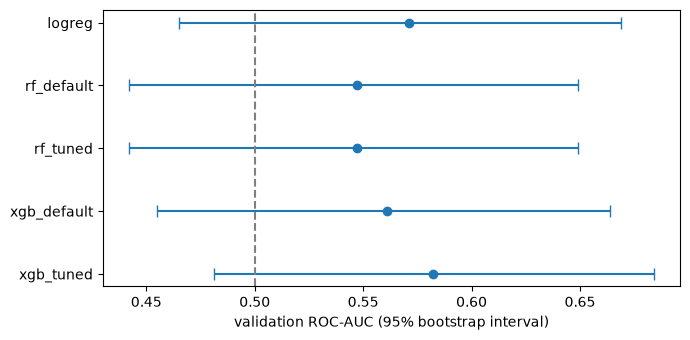

In [8]:
plot_df = comparison.drop(index="dummy")
auc = plot_df["roc_auc"]
err = np.vstack([auc - plot_df["auc_ci_low"], plot_df["auc_ci_high"] - auc])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(auc, range(len(plot_df)), xerr=err, fmt="o", capsize=4)
ax.axvline(0.5, linestyle="--", color="grey")
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df.index)
ax.invert_yaxis()
ax.set_xlabel("validation ROC-AUC (95% bootstrap interval)")
fig.tight_layout()
fig.savefig("docs/figures/day18_val_auc_ci.png", dpi=150)
plt.show()

In [9]:
comparison.to_csv("docs/results/day18_comparison.csv")
selection_log.to_csv("docs/results/day18_selection_log.csv", index=False)


def to_markdown(df: pd.DataFrame) -> str:
    cols = ["model"] + list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [f"{v}" for v in row]) + " |")
    return "\n".join(lines)


print(to_markdown(comparison[["accuracy", "precision", "recall", "f1", "roc_auc", "auc_ci_low", "auc_ci_high"]]))

| model | accuracy | precision | recall | f1 | roc_auc | auc_ci_low | auc_ci_high |
|---|---|---|---|---|---|---|---|
| dummy | 0.598 | 0.0 | 0.0 | 0.0 | 0.5 | 0.5 | 0.5 |
| logreg | 0.583 | 0.458 | 0.216 | 0.293 | 0.571 | 0.465 | 0.669 |
| rf_default | 0.449 | 0.404 | 0.784 | 0.533 | 0.547 | 0.442 | 0.649 |
| rf_tuned | 0.449 | 0.404 | 0.784 | 0.533 | 0.547 | 0.442 | 0.649 |
| xgb_default | 0.48 | 0.416 | 0.725 | 0.529 | 0.561 | 0.455 | 0.664 |
| xgb_tuned | 0.543 | 0.448 | 0.588 | 0.508 | 0.582 | 0.481 | 0.684 |


## Observations

1. Logreg is the selected model
2. logreg: val ROC-AUC 0.571, 95% CI [0.465, 0.669]
